# Physical AI Lab — Python to Robotics Perception
### A step-by-step Google Colab project

**Goal:** build one learning pipeline that connects Python, computer vision, deep learning inference, 3D geometry, visual motion, and performance measurement.

**How to use this notebook**
1. Upload this `.ipynb` to Google Colab.
2. Select **Runtime → Change runtime type → T4 GPU** if available. CPU is fine for the early lessons.
3. Run cells from top to bottom.
4. Read the explanation, run the experiment, then complete the exercises before moving on.

**Learning rule:** first make it correct, then measure it, then optimize it. Results depend on the Colab runtime and available hardware; do not treat example timings as universal benchmarks.

**Roadmap**
1. Python + NumPy · 2. Images as arrays · 3. Profiling · 4. Image geometry · 5. Feature matching · 6. PyTorch · 7. Object detection · 8. Camera calibration · 9. Depth-to-3D · 10. Motion estimation · 11. ONNX/quantization concepts · 12. Integrated mini-pipeline.


## 0. Environment and hardware check

We use OpenCV for computer vision, NumPy for array operations, Matplotlib for visualization, and PyTorch for neural-network inference. These are common building blocks in perception systems.

If Colab already has compatible versions installed, avoid upgrading everything unnecessarily.

In [1]:
import sys, time, platform, os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU. Early lessons work without a GPU.")

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams["figure.figsize"] = (10, 5)


Python: 3.11.17
Platform: Linux-7.0.0-38-generic-x86_64-with-glibc2.43
NumPy: 1.26.4
OpenCV: 4.11.0
PyTorch: 2.14.1+cpu
CUDA available: False
Running on CPU. Early lessons work without a GPU.


## 1. Python foundations: arrays, functions, and vectorization

Robotics software handles streams of numbers: pixels, coordinates, sensor readings, and model outputs. NumPy arrays let us process these efficiently.

A grayscale image is a 2D array `(height, width)`. A color image is usually a 3D array `(height, width, channels)`.

In [2]:
# A tiny synthetic sensor reading
sensor_readings = np.array([1.2, 1.4, 1.1, 1.8, 2.0], dtype=np.float32)

def normalize(values):
    values = np.asarray(values, dtype=np.float32)
    lo, hi = values.min(), values.max()
    if hi == lo:
        return np.zeros_like(values)
    return (values - lo) / (hi - lo)

print("Raw readings:", sensor_readings)
print("Normalized:", normalize(sensor_readings))
print("Shape:", sensor_readings.shape, "| dtype:", sensor_readings.dtype)

# Vectorized computation: no Python loop needed
distances_m = np.array([0.7, 1.4, 2.3, 4.0], dtype=np.float32)
distances_cm = distances_m * 100
print("Centimeters:", distances_cm)


Raw readings: [1.2 1.4 1.1 1.8 2. ]
Normalized: [0.11111114 0.33333328 0.         0.77777773 1.        ]
Shape: (5,) | dtype: float32
Centimeters: [ 70. 140. 230. 400.]


**Exercise 1**
- Add a function that converts meters per second to kilometers per hour.
- Create 100 simulated sensor readings and calculate their mean and standard deviation.
- Why is the array's `dtype` important when working with memory-limited devices?

## 2. Images are arrays

We'll create a reproducible synthetic scene so the notebook doesn't depend on a dataset download. Later lessons use this scene to demonstrate gradients, feature detection, and motion estimation.

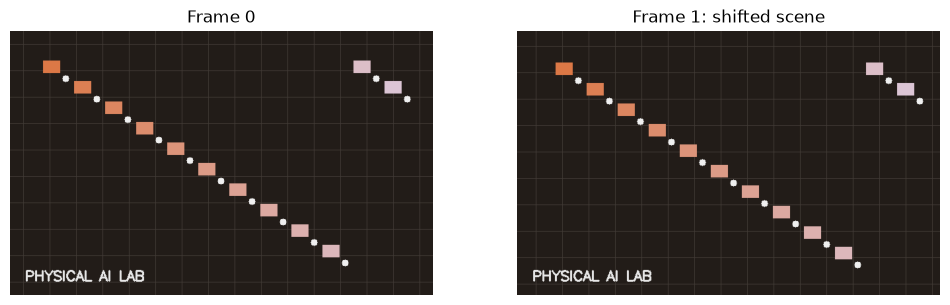

Image shape: (400, 640, 3) means (BGR): [30.06005859 34.3736875  41.65381641]


In [3]:
def make_scene(width=640, height=400, shift_x=0, shift_y=0):
    image = np.zeros((height, width, 3), dtype=np.uint8)
    image[:] = (24, 28, 34)
    # Grid and high-contrast shapes create trackable features
    for x in range(20, width, 40):
        cv2.line(image, (x + shift_x, 0), (x + shift_x, height-1), (55, 60, 67), 1)
    for y in range(20, height, 40):
        cv2.line(image, (0, y + shift_y), (width-1, y + shift_y), (55, 60, 67), 1)
    for i in range(12):
        x = 50 + (i * 47) % (width - 100)
        y = 45 + (i * 31) % (height - 90)
        x = int((x + shift_x) % width)
        y = int((y + shift_y) % height)
        cv2.rectangle(image, (x, y), (min(x+25, width-1), min(y+18, height-1)),
                      (70 + (i*13)%180, 120 + (i*7)%120, 220), -1)
        cv2.circle(image, (min(x+34, width-1), min(y+27, height-1)), 5, (240, 240, 240), -1)
    cv2.putText(image, "PHYSICAL AI LAB", (22, height-22),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (230,230,230), 2)
    return image

frame0 = make_scene()
frame1 = make_scene(shift_x=8, shift_y=3)

plt.figure(figsize=(12, 4))
plt.subplot(1,2,1); plt.imshow(cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB)); plt.title("Frame 0"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB)); plt.title("Frame 1: shifted scene"); plt.axis("off")
plt.show()
print("Image shape:", frame0.shape, "means (BGR):", frame0.mean(axis=(0,1)))


**Concept check:** OpenCV commonly stores color images as BGR, while Matplotlib expects RGB. That is why the display converts color order.

**Exercise 2:** crop the image, resize it to half width and height, and report the memory size in bytes using `image.nbytes`. Compare `uint8` with `float32`.

In [4]:
crop = frame0[40:240, 60:360]
small = cv2.resize(frame0, (frame0.shape[1]//2, frame0.shape[0]//2))
print("Original:", frame0.shape, frame0.nbytes, "bytes")
print("Crop:", crop.shape, crop.nbytes, "bytes")
print("Half-size:", small.shape, small.nbytes, "bytes")
print("Same dimensions as original?", small.shape == frame0.shape)


Original: (400, 640, 3) 768000 bytes
Crop: (200, 300, 3) 180000 bytes
Half-size: (200, 320, 3) 192000 bytes
Same dimensions as original? False


## 3. Measure before optimizing: latency and throughput

- **Latency**: time needed for one operation.
- **Throughput**: amount of work completed per second.
- **FPS**: frames processed per second.

This microbenchmark compares a Python loop with a vectorized NumPy operation. It is a teaching example, not a GPU benchmark.

In [5]:
rng = np.random.default_rng(SEED)
values = rng.random(1_000_000, dtype=np.float32)

def python_square_sum(arr):
    total = 0.0
    for x in arr:
        total += float(x) * float(x)
    return total

t0 = time.perf_counter()
result_numpy = float(np.sum(values * values))
numpy_seconds = time.perf_counter() - t0

# Use a smaller input for the Python loop to keep the lesson responsive
subset = values[:100_000]
t0 = time.perf_counter()
result_loop = python_square_sum(subset)
loop_seconds = time.perf_counter() - t0

print(f"NumPy: {numpy_seconds*1000:.2f} ms for 1,000,000 values")
print(f"Python loop: {loop_seconds*1000:.2f} ms for 100,000 values")
print("Results differ because the input sizes differ.")


NumPy: 2.37 ms for 1,000,000 values
Python loop: 9.28 ms for 100,000 values
Results differ because the input sizes differ.


**Exercise 3**
1. Repeat the NumPy calculation five times and report the median.
2. Try a 10,000-element Python loop.
3. Explain why benchmarking one run can be misleading (startup, caching, background load, and variable hardware).
4. Avoid comparing timings unless the input sizes and work are equivalent.

## 4. Image processing: edges and line structure

Edges and lines can help describe scene geometry. They are not a complete localization system, but they are useful building blocks.

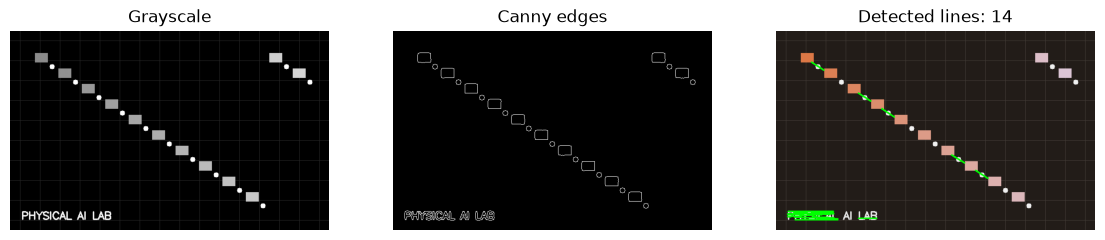

In [6]:
gray = cv2.cvtColor(frame0, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5,5), 0)
edges = cv2.Canny(blur, 60, 150)
lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=45,
                        minLineLength=25, maxLineGap=8)

line_view = frame0.copy()
# OpenCV 4 returns (N, 1, 4). OpenCV 5 returns (N, 4).
if lines is not None:
    for x1, y1, x2, y2 in np.asarray(lines).reshape(-1, 4):
        cv2.line(line_view, (int(x1), int(y1)), (int(x2), int(y2)), (0,255,0), 2)

plt.figure(figsize=(14,4))
plt.subplot(1,3,1); plt.imshow(gray, cmap="gray"); plt.title("Grayscale"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(edges, cmap="gray"); plt.title("Canny edges"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(cv2.cvtColor(line_view, cv2.COLOR_BGR2RGB)); plt.title(f"Detected lines: {0 if lines is None else len(lines)}"); plt.axis("off")
plt.show()


**Exercise 4:** change the Canny thresholds and Hough parameters. Note which settings create too many fragments or miss important edges. In a real system, thresholds should be tested across varied lighting and scenes.

## 5. Keypoints and matching between frames

Visual odometry often starts by finding distinctive image points, matching them across frames, then using camera geometry to estimate motion. Here the second image is a synthetic shift, so we know the scene was moved by about 8 pixels horizontally and 3 vertically.

This is a 2D image shift—not a full 3D camera-motion estimate.

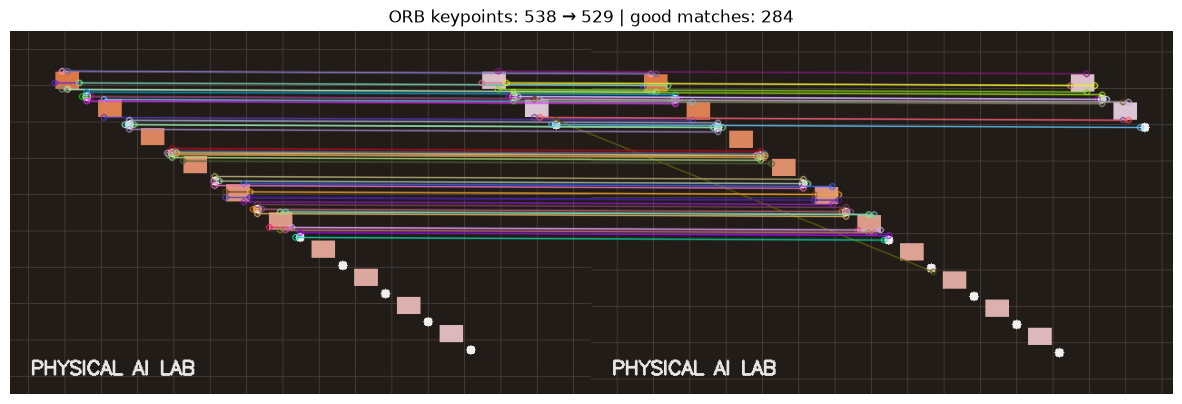

Keypoints: 538 529 | accepted matches: 284


In [7]:
orb = cv2.ORB_create(nfeatures=1000)
g0 = cv2.cvtColor(frame0, cv2.COLOR_BGR2GRAY)
g1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
kp0, des0 = orb.detectAndCompute(g0, None)
kp1, des1 = orb.detectAndCompute(g1, None)

matches = []
if des0 is not None and des1 is not None:
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    pairs = matcher.knnMatch(des0, des1, k=2)
    matches = [m for pair in pairs if len(pair) == 2
               for m,n in [pair] if m.distance < 0.75*n.distance]

matched_view = cv2.drawMatches(frame0, kp0, frame1, kp1, matches[:60], None,
                               flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(15,6))
plt.imshow(cv2.cvtColor(matched_view, cv2.COLOR_BGR2RGB))
plt.title(f"ORB keypoints: {len(kp0)} → {len(kp1)} | good matches: {len(matches)}")
plt.axis("off"); plt.show()
print("Keypoints:", len(kp0), len(kp1), "| accepted matches:", len(matches))


**Exercise 5**
- Try changing ORB's `nfeatures`.
- Change the ratio threshold from `0.75` to `0.6` and `0.9`.
- Why do some matches remain incorrect?
- What extra steps would be needed to estimate real camera movement robustly? (Hint: outlier rejection, camera calibration, and geometric constraints.)

## 6. PyTorch tensors and device placement

A model's tensors and model weights must be on compatible devices. GPU acceleration is not guaranteed to help for tiny workloads because transferring data and launching kernels have overhead.

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
x = torch.randn(2048, 2048, device=device)
w = torch.randn(2048, 2048, device=device)

# Warm up the operation
_ = x @ w
if device.type == "cuda":
    torch.cuda.synchronize()

t0 = time.perf_counter()
y = x @ w
if device.type == "cuda":
    torch.cuda.synchronize()
elapsed = time.perf_counter() - t0

print("Device:", device)
print("Input shape:", tuple(x.shape), "Output shape:", tuple(y.shape))
print(f"One matrix multiplication: {elapsed*1000:.2f} ms")


Device: cpu
Input shape: (2048, 2048) Output shape: (2048, 2048)
One matrix multiplication: 83.24 ms


**Important GPU timing detail:** CUDA operations are often asynchronous. `torch.cuda.synchronize()` ensures queued GPU work has completed before measuring elapsed time.

**Exercise 6:** try matrix sizes 512, 1024, and 2048. Run each several times. Compare only like-for-like runs and note which device Colab assigned.

## 7. Run a pretrained object detector

This optional section uses a pretrained detector from TorchVision. The first run may download model weights and requires internet access. The model is for learning, not safety-critical use. If model loading fails because the runtime's TorchVision installation is incompatible, skip this section and continue.

We run detection on our synthetic image, which is not a natural photograph, so poor or empty detections are expected. For meaningful results, test a real image you have permission to use.

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /home/ahmad/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


  0%|          | 0.00/160M [00:00<?, ?B/s]

  1%|▏         | 2.12M/160M [00:00<00:07, 21.6MB/s]

  3%|▎         | 4.62M/160M [00:00<00:06, 24.0MB/s]

  5%|▍         | 7.38M/160M [00:00<00:06, 26.1MB/s]

...

 94%|█████████▍| 151M/160M [00:06<00:00, 26.6MB/s]

 96%|█████████▌| 153M/160M [00:06<00:00, 26.8MB/s]

 98%|█████████▊| 156M/160M [00:07<00:00, 27.2MB/s]

 99%|█████████▉| 159M/160M [00:07<00:00, 27.8MB/s]

100%|██████████| 160M/160M [00:07<00:00, 23.4MB/s]

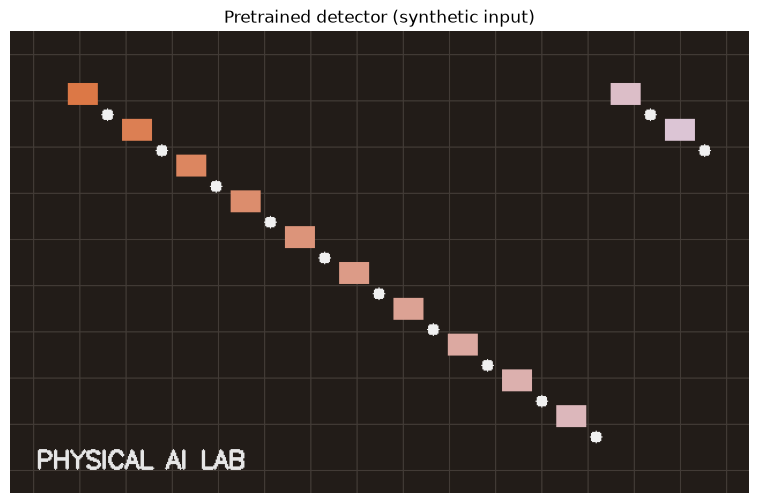

Predictions above threshold: 0


In [9]:
from PIL import Image
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
detector = fasterrcnn_resnet50_fpn(weights=weights).to(device).eval()
preprocess = weights.transforms()

rgb = cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB)
tensor_image = preprocess(Image.fromarray(rgb)).to(device)

with torch.inference_mode():
    prediction = detector([tensor_image])[0]

labels = weights.meta["categories"]
scores = prediction["scores"].detach().cpu().numpy()
boxes = prediction["boxes"].detach().cpu().numpy()
classes = prediction["labels"].detach().cpu().numpy()

vis = rgb.copy()
threshold = 0.5
for box, score, cls in zip(boxes, scores, classes):
    if score < threshold:
        continue
    x1,y1,x2,y2 = box.astype(int)
    cv2.rectangle(vis, (x1,y1), (x2,y2), (0,255,0), 2)
    label = f"{labels[int(cls)]}: {score:.2f}"
    cv2.putText(vis, label, (x1, max(18,y1-5)), cv2.FONT_HERSHEY_SIMPLEX,
                0.5, (0,255,0), 1, cv2.LINE_AA)

plt.figure(figsize=(12,6))
plt.imshow(vis); plt.title("Pretrained detector (synthetic input)"); plt.axis("off"); plt.show()
print("Predictions above threshold:", int((scores >= threshold).sum()))


**Exercise 7:** run the detector on a real photo. Record the confidence threshold, number of detections, image dimensions, and latency. Don't assume a high confidence score means a prediction is correct.

## 8. Camera geometry: pixels, rays, and calibration

A pinhole camera model relates a 3D point to its pixel coordinates. For a point `(X, Y, Z)` in camera coordinates:

`u = fx * X/Z + cx` and `v = fy * Y/Z + cy`

`fx, fy` are focal lengths in pixels; `(cx, cy)` is the principal point. We'll use example parameters, not a real camera calibration.

In [10]:
width, height = 640, 400
fx, fy = 520.0, 520.0
cx, cy = width/2, height/2

K = np.array([[fx, 0, cx],
              [0, fy, cy],
              [0,  0,  1]], dtype=np.float64)
print("Camera intrinsic matrix K:\n", K)

# Project a 3D point in front of the camera to image coordinates
point_camera = np.array([0.25, -0.10, 2.0])  # meters
X, Y, Z = point_camera
u = fx * X/Z + cx
v = fy * Y/Z + cy
print(f"3D point {point_camera} m -> pixel ({u:.1f}, {v:.1f})")

# Back-project pixel + depth into camera coordinates
depth_m = Z
X_back = (u-cx) * depth_m / fx
Y_back = (v-cy) * depth_m / fy
print("Back-projected point (m):", [X_back, Y_back, depth_m])


Camera intrinsic matrix K:
 [[520.   0. 320.]
 [  0. 520. 200.]
 [  0.   0.   1.]]
3D point [ 0.25 -0.1   2.  ] m -> pixel (385.0, 174.0)
Back-projected point (m): [0.25, -0.1, 2.0]


**Exercise 8:** change the depth while keeping X and Y fixed. Observe how pixel location changes. Then change focal length. In practice, camera intrinsics should be estimated from calibration images, not guessed.

## 9. Depth map to a 3D point cloud

A depth map gives a distance for each pixel. Using camera intrinsics, each valid pixel can be back-projected into a 3D point. We create a synthetic depth map for this lesson; it is not a measurement from a real sensor.

Point cloud shape: (38400, 3)
First five XYZ points (meters):
 [[-1.09090909 -0.72727273  2.        ]
 [-1.08344091 -0.72836364  2.003     ]
 [-1.07594545 -0.72945455  2.006     ]
 [-1.06842273 -0.73054545  2.009     ]
 [-1.06087273 -0.73163636  2.012     ]]


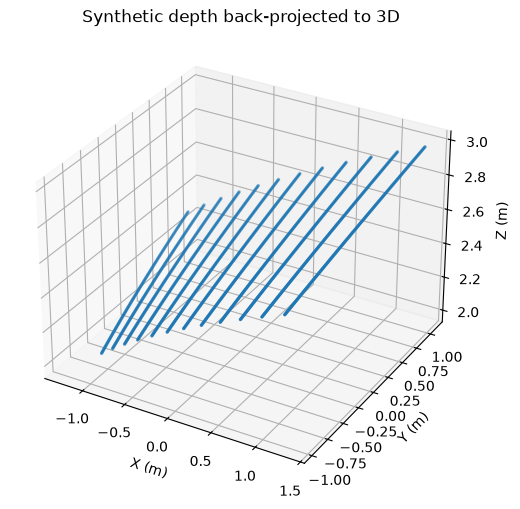

In [11]:
h, w = 160, 240
yy, xx = np.mgrid[0:h, 0:w]
depth = 2.0 + 0.003*xx + 0.002*yy  # synthetic depth in meters
fx_p, fy_p = 220.0, 220.0
cx_p, cy_p = w/2, h/2

X = (xx - cx_p) * depth / fx_p
Y = (yy - cy_p) * depth / fy_p
Z = depth
points = np.stack([X, Y, Z], axis=-1).reshape(-1, 3)

valid = np.isfinite(points).all(axis=1) & (points[:,2] > 0)
points = points[valid]
print("Point cloud shape:", points.shape)
print("First five XYZ points (meters):\n", points[:5])

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")
sample = points[::20]
ax.scatter(sample[:,0], sample[:,1], sample[:,2], s=2)
ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)"); ax.set_zlabel("Z (m)")
ax.set_title("Synthetic depth back-projected to 3D")
plt.show()


**Exercise 9**
- Exclude points with depth greater than 2.5 m.
- Add random depth noise and visualize its effect.
- Why do invalid depth values and calibration errors create bad point clouds?
- Real depth sensors have uncertainty, missing pixels, and range limits.

## 10. Estimate 2D image motion (a bridge toward visual odometry)

Before full visual odometry, estimate the dominant 2D translation between two images using phase correlation. It recovers a pure image translation. The redrawn scene is not a pure translation: shapes wrap around the borders and the label stays fixed, so that pair stays near zero shift. A rolled copy of frame 0 is a pure translation of +8 px and +3 px, and phase correlation recovers it. Real camera motion is more complicated because of rotation, perspective, depth variation, and moving objects.


In [ ]:
g0f = np.float32(cv2.cvtColor(frame0, cv2.COLOR_BGR2GRAY))
g1f = np.float32(cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY))
(dx, dy), response = cv2.phaseCorrelate(g0f, g1f)
print(f"Redrawn scene: dx={dx:.2f}px, dy={dy:.2f}px, response={response:.3f}")

translated = np.roll(frame0, shift=(3, 8), axis=(0, 1))
gt = np.float32(cv2.cvtColor(translated, cv2.COLOR_BGR2GRAY))
(dx_t, dy_t), response_t = cv2.phaseCorrelate(g0f, gt)
print(f"Pure +8 px, +3 px translation: dx={dx_t:.2f}px, dy={dy_t:.2f}px, response={response_t:.3f}")


**Exercise 10:** test shifts of `(0, 0)`, `(15, 0)`, and `(0, 12)`. Does the estimate follow the change? Try to explain why this does not directly give meters of camera travel.

**Toward true visual odometry:** use calibrated camera images, match features, reject outliers with RANSAC, estimate an essential matrix, and recover relative pose. Monocular motion typically has an unknown scale without an additional source of depth or motion information.

## 11. Quantization and deployment: understand the trade-offs

Quantization represents model values with lower precision, often reducing memory use and sometimes improving inference speed on supported hardware. It can also reduce accuracy. Actual benefit depends on the model, operators, runtime, and device.

This small experiment illustrates storage cost only. It does **not** quantize a neural network or prove an inference speedup.

In [13]:
weights_demo = np.random.default_rng(SEED).normal(size=1_000_000).astype(np.float32)
weights_int8_demo = np.clip(np.round(weights_demo * 32), -128, 127).astype(np.int8)

print("FP32 storage:", weights_demo.nbytes, "bytes")
print("INT8 storage:", weights_int8_demo.nbytes, "bytes")
print("Storage ratio:", round(weights_demo.nbytes / weights_int8_demo.nbytes, 1), "x")

reconstructed = weights_int8_demo.astype(np.float32) / 32
print("Mean absolute quantization error:", np.mean(np.abs(weights_demo-reconstructed)))


FP32 storage: 4000000 bytes
INT8 storage: 1000000 bytes
Storage ratio: 4.0 x
Mean absolute quantization error: 0.007819176


**Exercise 11:** change the scale factor `32`. How does quantization error change? Values outside the representable range are clipped, which introduces additional error.

**Deployment concepts to investigate next**
- Export a supported PyTorch model to ONNX.
- Validate ONNX outputs against the original model.
- Benchmark the ONNX Runtime CPU execution provider.
- If a compatible GPU and runtime are available, compare supported GPU execution.
- TensorRT requires a compatible NVIDIA environment; it is not guaranteed to be installed in Colab.
- Edge accelerators such as Metis require their own supported toolchain and hardware.

## 12. Integrate the concepts: a tiny perception pipeline

This first integrated pipeline uses classical computer vision rather than a large neural network. It processes a frame, extracts edges and features, and records per-stage timing. Later, swap in object detection and depth estimation.

The purpose is to establish a repeatable measurement pattern.

Keypoints: 476
Stage timings: {'grayscale_ms': 0.2508969996597443, 'edges_ms': 1.5082969998729823, 'orb_ms': 5.11934599990127}
Total measured stage time: 6.878539999433997 ms


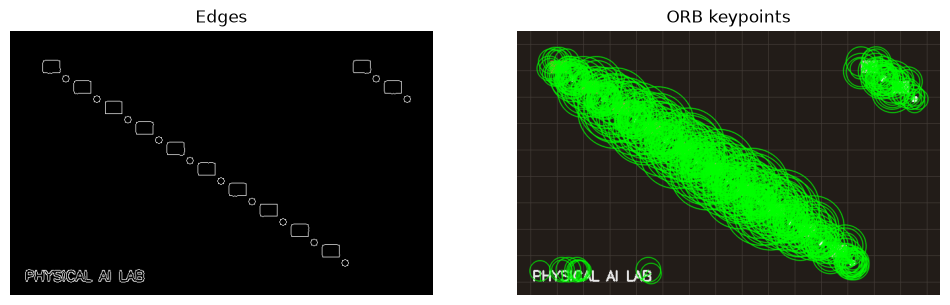

In [14]:
def process_frame(image):
    timings = {}
    t0 = time.perf_counter()
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    timings["grayscale_ms"] = (time.perf_counter()-t0)*1000

    t0 = time.perf_counter()
    edges = cv2.Canny(cv2.GaussianBlur(gray, (5,5), 0), 60, 150)
    timings["edges_ms"] = (time.perf_counter()-t0)*1000

    t0 = time.perf_counter()
    keypoints, descriptors = cv2.ORB_create(nfeatures=500).detectAndCompute(gray, None)
    timings["orb_ms"] = (time.perf_counter()-t0)*1000

    return {"gray": gray, "edges": edges, "keypoints": keypoints,
            "descriptors": descriptors, "timings_ms": timings}

output = process_frame(frame0)
print("Keypoints:", len(output["keypoints"]))
print("Stage timings:", output["timings_ms"])
print("Total measured stage time:", sum(output["timings_ms"].values()), "ms")

vis = cv2.drawKeypoints(frame0, output["keypoints"], None,
                        color=(0,255,0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.imshow(output["edges"], cmap="gray"); plt.title("Edges"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.title("ORB keypoints"); plt.axis("off")
plt.show()


## 13. Benchmark multiple frames

Single-frame timings are noisy. Run a batch and summarize median and 95th-percentile stage latency. These are software timings on your current Colab runtime, not end-to-end robot latency.

In [15]:
frames = [make_scene(shift_x=i*2, shift_y=i) for i in range(20)]
records = []
for frame in frames:
    records.append(process_frame(frame)["timings_ms"])

stage_names = records[0].keys()
for stage in stage_names:
    vals = np.array([r[stage] for r in records])
    print(f"{stage:16s} median={np.median(vals):7.2f} ms | p95={np.percentile(vals,95):7.2f} ms")

total_median_ms = np.median([sum(r.values()) for r in records])
print(f"Approximate throughput based on median stage time: {1000/total_median_ms:.1f} frames/s")


grayscale_ms     median=   0.13 ms | p95=   0.19 ms
edges_ms         median=   0.35 ms | p95=   0.59 ms
orb_ms           median=   4.00 ms | p95=   4.22 ms
Approximate throughput based on median stage time: 222.3 frames/s


**Benchmarking checklist**
- Use the same input size and model when comparing.
- Separate model loading and warm-up from steady-state inference.
- Measure end-to-end latency as well as individual stages.
- Include preprocessing, data transfer, and postprocessing when relevant.
- Record hardware, software versions, precision, and batch size.
- Don't call a pipeline real-time merely because its average FPS looks high; deadlines and worst-case latency matter.

## 14. Final challenge: extend the lab

Choose a challenge and add it below this notebook:

**Beginner**
- Add a command-line-style configuration cell for image size and thresholds.
- Save benchmark results to CSV.
- Plot latency versus image resolution.

**Intermediate**
- Use a real video file and process every frame.
- Add optical flow using `cv2.calcOpticalFlowPyrLK`.
- Compare ORB and SIFT feature matching if SIFT is available.
- Run pretrained object detection on selected frames and measure latency.

**Advanced**
- Estimate relative camera pose from a calibrated image sequence using an essential matrix and RANSAC.
- Export a supported model to ONNX and compare outputs.
- Design a ROS 2 node interface for image input, detections, pose, and timing diagnostics.
- Add unit tests for coordinate transforms and camera projection.

### Your completion criteria
- [ ] I can explain the image array shape and data type.
- [ ] I can detect edges and match image features.
- [ ] I can explain what camera intrinsics do.
- [ ] I can convert valid depth pixels to 3D points.
- [ ] I can explain why monocular motion has scale ambiguity.
- [ ] I can benchmark latency and throughput correctly.
- [ ] I can distinguish a model demo from a deployable robotics pipeline.
- [ ] I can describe which parts should run on CPU, GPU, or a specialized accelerator.

### Suggested next project
Turn this notebook into a small repository with `src/`, `notebooks/`, `tests/`, `configs/`, and `results/`. Keep the notebook for exploration, and move stable functions into Python modules with tests. That is the first step from a Colab experiment toward production-quality robotics software.
